# Lab Assignment 9 – Cognitive AI
## Model 2: Emotion-Aware Cognitive Assistant using Facial Expression Detection

**Objective:** Build an assistant that analyses a face in an uploaded image and estimates the facial expression (for example, happy, sad, angry, surprised, fearful, disgusted, or neutral).

**How it works:** Upload image → detect face → classify facial expression using a pretrained vision model → show the predicted expression and confidence.

> **Responsible-use note:** Facial-expression models are imperfect and can be biased. A facial expression does not reliably reveal a person's actual feelings, intentions, personality, or mental health. Use this only as an educational demonstration, with consent, and never for high-stakes decisions.

Install required libraries

We use a pretrained image-classification model hosted on Hugging Face. The notebook downloads the model weights automatically; no training dataset or API key is required.

In [ ]:
!pip -q install transformers torch torchvision pillow opencv-python-headless matplotlib

 Import libraries and load the model

In [ ]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from transformers import pipeline
from google.colab import files

device = 0 if torch.cuda.is_available() else -1

emotion_model = pipeline(
    "image-classification",
    model="trpakov/vit-face-expression",
    device=device
)

print("Facial expression model loaded successfully.")
print("Using:", "GPU" if device == 0 else "CPU")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Facial expression model loaded successfully.
Using: CPU


 Upload a face image

Upload a JPG or PNG image containing a clearly visible face. Use an image you have permission to analyse.

Saving 7go5cgck_narendra-modi-pti_625x300_23_March_19.jpg to 7go5cgck_narendra-modi-pti_625x300_23_March_19 (1).jpg


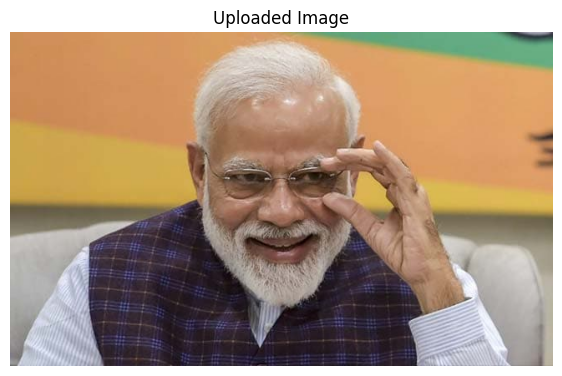

In [ ]:
uploaded = files.upload()
image_path = next(iter(uploaded.keys()))

image = Image.open(image_path).convert("RGB")
plt.figure(figsize=(7, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Uploaded Image")
plt.show()

 Detect the face

OpenCV's Haar Cascade detector finds a face region. If it cannot detect a face, the notebook will try classifying the full uploaded image instead.

OpenCV binding error encountered. Falling back to the full image.
No face detected by Haar Cascade. Trying the full image.


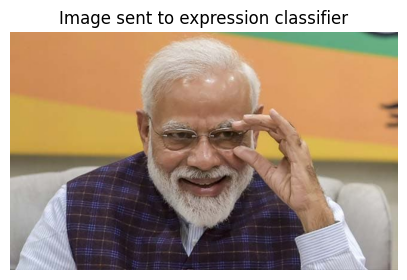

In [ ]:
import cv2

image_array = np.array(image)
gray = cv2.cvtColor(image_array, cv2.COLOR_RGB2GRAY)

# Ensure Haar Cascade classifier is initialized correctly
try:
    face_cascade = cv2.CascadeClassifier(
        cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
    )
    faces = face_cascade.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40)
    )
except AttributeError:
    # Fallback if cv2 doesn't bind CascadeClassifier properly
    print("OpenCV binding error encountered. Falling back to the full image.")
    faces = []

if len(faces) > 0:
    # Use the largest detected face
    x, y, w, h = max(faces, key=lambda box: box[2] * box[3])
    face_image = image.crop((x, y, x + w, y + h))
    print("Face detected.")
else:
    face_image = image
    print("No face detected by Haar Cascade. Trying the full image.")

plt.figure(figsize=(5, 5))
plt.imshow(face_image)
plt.axis("off")
plt.title("Image sent to expression classifier")
plt.show()

Predict the facial expression

The model returns a list of expression labels and confidence scores. These are model estimates, not confirmed emotions.

In [ ]:
predictions = emotion_model(face_image)

for item in predictions:
    print(f"{item['label']}: {item['score']:.4f}")

best_prediction = max(predictions, key=lambda item: item["score"])
predicted_expression = best_prediction["label"]
confidence = best_prediction["score"]

print("\\nPredicted expression:", predicted_expression)
print("Confidence:", round(confidence * 100, 2), "%")

happy: 0.9179
angry: 0.0536
surprise: 0.0084
fear: 0.0074
sad: 0.0061
\nPredicted expression: happy
Confidence: 91.79 %


Display prediction scores

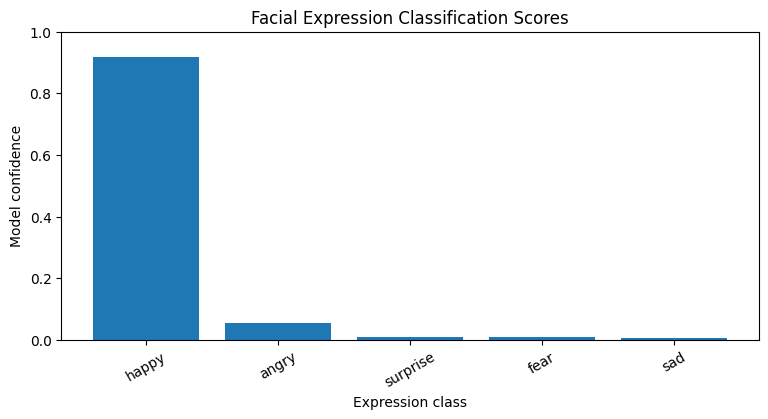

In [ ]:
labels = [item["label"] for item in predictions]
scores = [item["score"] for item in predictions]

plt.figure(figsize=(9, 4))
plt.bar(labels, scores)
plt.xlabel("Expression class")
plt.ylabel("Model confidence")
plt.title("Facial Expression Classification Scores")
plt.xticks(rotation=30)
plt.ylim(0, 1)
plt.show()

Emotion-aware assistant response

The response is intentionally neutral and does not assume what the person is actually feeling.

In [ ]:
print("EMOTION-AWARE COGNITIVE ASSISTANT")
print("-" * 45)
print("Most likely facial-expression class:", predicted_expression)
print("Model confidence:", f"{confidence * 100:.2f}%")
print("\\nAssistant: The image shows facial features most similar to the",
      predicted_expression, "class.")
print("Remember: a facial expression alone cannot tell us exactly how someone feels.")

EMOTION-AWARE COGNITIVE ASSISTANT
---------------------------------------------
Most likely facial-expression class: happy
Model confidence: 91.79%
\nAssistant: The image shows facial features most similar to the happy class.
Remember: a facial expression alone cannot tell us exactly how someone feels.


Save the prediction results

In [ ]:
import pandas as pd

results_df = pd.DataFrame(predictions)
results_df.to_csv("facial_expression_predictions.csv", index=False)
files.download("facial_expression_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Conclusion

The Emotion-Aware Cognitive Assistant uses a pretrained Vision Transformer image-classification model to estimate facial-expression classes. OpenCV is used to locate a face, and the classifier produces class scores that are displayed as a chart and assistant response. The result is only an estimate of visible facial expression, not a reliable measurement of a person's internal emotional state.